# Practical 12 — Retail Sales Aggregation

Create retail transactions, group sales by region and product category, and compare the results using bar and pie charts.

**Run the cells from top to bottom.** The dataset is generated inside this notebook before the practical begins.

## 1. Install / import requirements

If a package is missing, run `!pip install pandas numpy matplotlib seaborn scikit-learn statsmodels openpyxl requests xgboost` in a notebook cell. Most environments already have the common packages.

In [1]:
from pathlib import Path
Path('data').mkdir(exist_ok=True)


## 2. Create the required dataset

This is the relevant part of `make_data.py`, placed here so the notebook is self-contained.

In [2]:
# Create synthetic retail transactions for aggregation.
import numpy as np, pandas as pd
rng=np.random.default_rng(42); n=800
retail=pd.DataFrame({"TransactionDate":pd.date_range("2024-01-01",periods=n,freq="6h").strftime("%Y-%m-%d"),
 "Region":rng.choice(["North","South","East","West"],n,p=[.35,.25,.2,.2]),
 "ProductCategory":rng.choice(["Electronics","Clothing","Grocery","Toys"],n),
 "QuantitySold":rng.integers(1,20,n),"SalesAmount":rng.uniform(50,2000,n).round(2)})
retail.to_csv("data/Retail_Sales_Data.csv",index=False)
print("Created data/Retail_Sales_Data.csv")


Created data/Retail_Sales_Data.csv


## 3. Practical implementation

The following cells perform the analysis and show the output.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   TransactionDate  800 non-null    object 
 1   Region           800 non-null    object 
 2   ProductCategory  800 non-null    object 
 3   QuantitySold     800 non-null    int64  
 4   SalesAmount      800 non-null    float64
dtypes: float64(1), int64(1), object(3)
memory usage: 31.4+ KB
  TransactionDate Region ProductCategory  QuantitySold  SalesAmount
0      2024-01-01   East        Clothing             1      1830.91
1      2024-01-01  South         Grocery            11       323.11
2      2024-01-01   West            Toys            15      1371.53
3      2024-01-01   East        Clothing            11      1638.22
4      2024-01-02  North     Electronics             8       508.75
None
Region
North    296640.88
South    192650.57
East     162261.87
West     159007.39
Name: SalesAmou

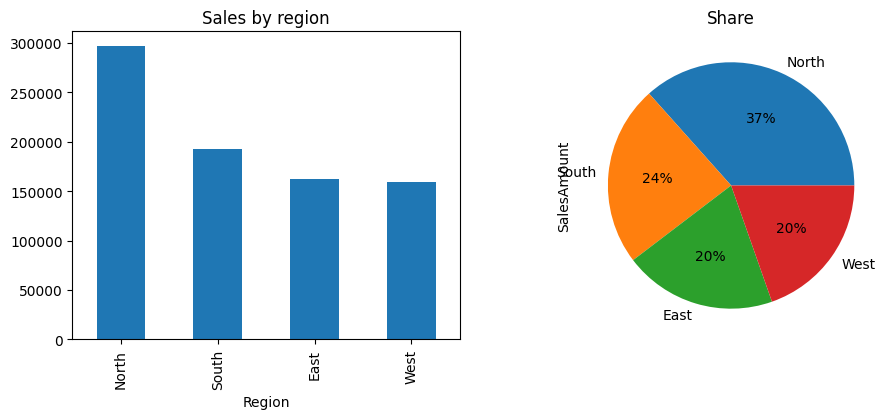

ProductCategory  Clothing  Electronics   Grocery      Toys
Region                                                    
East             45958.80     36646.66  38110.93  41545.48
North            78127.15     76068.68  65562.47  76882.58
South            50928.57     50437.74  44982.62  46301.64
West             39875.42     36391.27  40060.81  42679.89


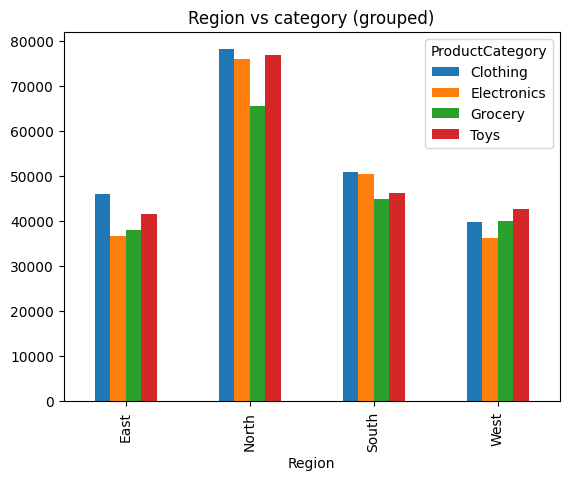

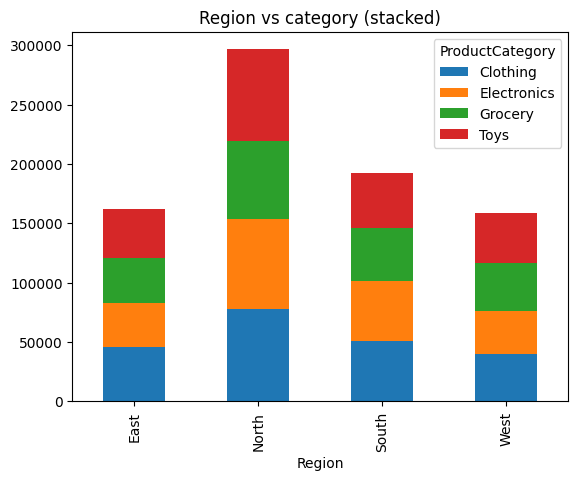

In [3]:
import pandas as pd, matplotlib.pyplot as plt

df = pd.read_csv("data/Retail_Sales_Data.csv")
print(df.head(), df.info(), sep="\n")

by_region = df.groupby("Region").SalesAmount.sum().sort_values(ascending=False)   # total per region
print(by_region.round(2))
print("Top region:", by_region.idxmax())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
by_region.plot.bar(ax=ax[0], title="Sales by region")
by_region.plot.pie(ax=ax[1], autopct="%1.0f%%", title="Share"); plt.show()

combo = df.groupby(["Region", "ProductCategory"]).SalesAmount.sum().unstack()     # region x category
print(combo.round(2))
combo.plot.bar(title="Region vs category (grouped)"); plt.show()
combo.plot.bar(stacked=True, title="Region vs category (stacked)"); plt.show()